# 주10: crossover

**202315163 김소희**

SK하이닉스(000660)의 2026년 8월과 9월 일간 주가로 이동평균과 조건부 수익률 누적합을 계산한다.

## 1. 주가 수집과 데이터프레임 생성

FinanceDataReader로 2026-08-01~2026-09-30의 거래일 자료를 수집한다. 가격 단위는 원이다.

FinanceDataReader가 없다면 노트북의 Python 환경에서 설치 명령 `!pip install finance-datareader`를 먼저 실행한다.

In [1]:
import FinanceDataReader as fdr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

start = '2026-08-01'
end = '2026-09-30'

df = fdr.DataReader('000660', start, end)
df = df[['Open', 'High', 'Low', 'Close', 'Volume']].copy()
df = df.sort_index()

print('종목: SK하이닉스 (000660)')
print(f'조회 기간: {start} ~ {end}')
print(f'실제 자료 기간: {df.index[0]:%Y-%m-%d} ~ {df.index[-1]:%Y-%m-%d}')
print(f'거래일 수: {len(df)}일')

종목: SK하이닉스 (000660)
조회 기간: 2026-08-01 ~ 2026-09-30
실제 자료 기간: 2026-08-03 ~ 2026-09-30
거래일 수: 40일


## 2. 5일 이동평균과 20일 이동평균과 비교값

`ma5`, `ma20`은 현재 거래일을 포함한 최근 5거래일과 20거래일 종가의 평균이다.
`position`은 `ma5 > ma20`이면 1, 같으면 0, 작으면 -1이다.
처음 4일의 `ma5`와 처음 19일의 `ma20`은 자료 부족으로 `NaN`이며, 비교 불가 구간의 `position`도 `NaN`으로 둔다.

In [2]:
df['ma5'] = df['Close'].rolling(window=5).mean()
df['ma20'] = df['Close'].rolling(window=20).mean()

df['position'] = np.where(
    df['ma5'] > df['ma20'], 1,
    np.where(df['ma5'] < df['ma20'], -1, 0)
)

# ma20이 없는 초기 구간은 '같음(0)'이 아니라 '비교 불가(NaN)'이다.
df['position'] = df['position'].where(~df['ma20'].isna())

## 3. 비교값이 1인 날의 수익률 누적합

누적합은 `ma5 > ma20`인 날의 일별 수익률만 처음부터 현재까지 차례로 더한 값이다. 해당하지 않는 날은 이전 값이 유지된다.

In [3]:
# 일별 단순수익률 = 현재 종가 / 전일 종가 - 1
df['returnsDaily'] = df['Close'].pct_change()

# 당일 비교값으로 당일 수익률을 선택한다.
df['returnsDailyCum'] = (
    df['returnsDaily'].where(df['position'] == 1).fillna(0).cumsum()
)

## 4. 추가된 컬럼을 포함한 데이터프레임 출력

In [4]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

df

,Open,High,Low,Close,Volume,ma5,ma20,position,returnsDaily,returnsDailyCum
Date,,,,,,,,,,
2026-08-03,1642000,1645000,1562000,1567000,5432833,NaN,NaN,NaN,NaN,0.000000
2026-08-04,1620000,1630000,1483000,1577000,5391210,NaN,NaN,NaN,0.006382,0.000000
2026-08-05,1693000,1701000,1647000,1668000,3945674,NaN,NaN,NaN,0.057705,0.000000
2026-08-06,1600000,1606000,1481000,1495000,5498295,NaN,NaN,NaN,-0.103717,0.000000
2026-08-07,1521000,1542000,1409000,1422000,5002539,1545800.0,NaN,NaN,-0.048829,0.000000
2026-08-10,1443000,1487000,1397000,1420000,3295283,1516400.0,NaN,NaN,-0.001406,0.000000
2026-08-11,1405000,1455000,1373000,1425000,3817655,1486000.0,NaN,NaN,0.003521,0.000000
2026-08-12,1456000,1549000,1440000,1504000,4566672,1453200.0,NaN,NaN,0.055439,0.000000
2026-08-13,1582000,1634000,1567000,1593000,4680347,1472800.0,NaN,NaN,0.059176,0.000000


## 5. 주가와 두 이동평균 차트

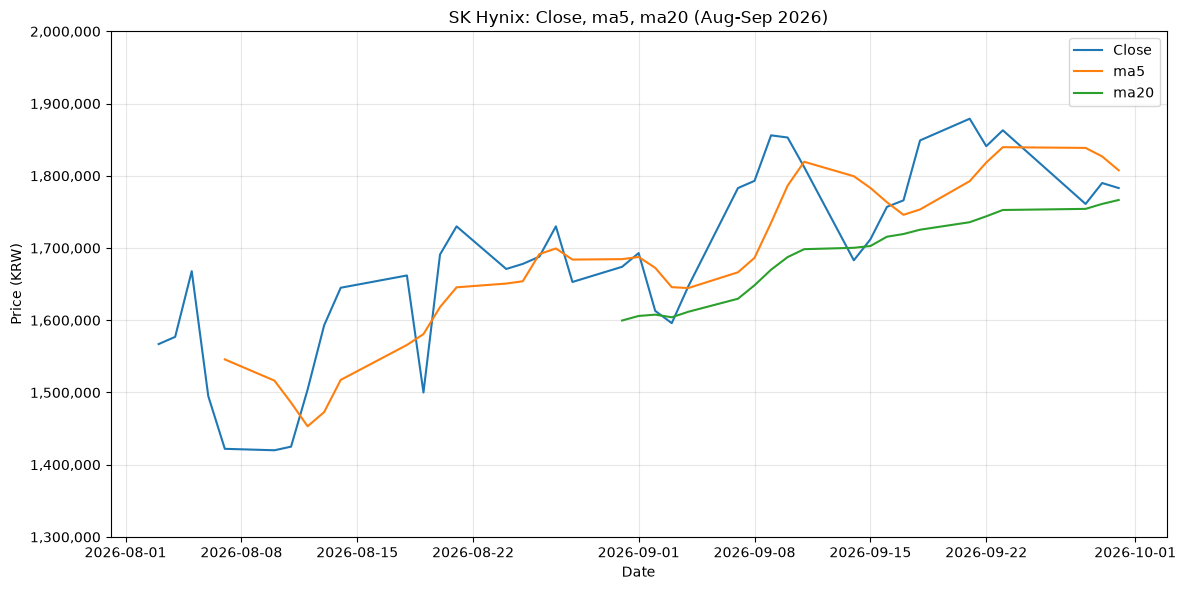

In [5]:
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['Close'], label='Close')
plt.plot(df.index, df['ma5'], label='ma5')
plt.plot(df.index, df['ma20'], label='ma20')
plt.title('SK Hynix: Close, ma5, ma20 (Aug-Sep 2026)')
plt.xlabel('Date')
plt.ylabel('Price (KRW)')
plt.legend()
plt.grid(True, alpha=0.3)
ticks = plt.yticks()[0]
plt.yticks(ticks, [f'{value:,.0f}' for value in ticks])
plt.tight_layout()
plt.show()